## scMAVERICS - multiome integration

The word integration is used a lot in single cell analysis. In this context, multiome integration really means the combining of gene expression and chromatin accessibility modalities across all samples in a dataset. The resulting object at the end of this processing step will be the final object from which all multiome analyses can be based. For analysis specific to chromatin accessibility peaksets unique to cell types and/or diagnosis state binning, proceed to the next section [Peak calling](peaks.md).

**🚨 HALT! 🚨**

This section assumes you have completed the previous section, [snRNAseq preprocessing](snRNAseq.md) and [snATACseq preprocessing](snATACseq.md), with the object `06_QC_filtered_anndata_rna.h5ad` and `04_modeled_anndata_atac.h5ad` in the `atlas` folder. If not, go back and complete the analysis, preferably with the Snakemake pipeline.

## Package and data loading

In [87]:
import gc
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import muon as mu
import snapatac2 as snap
import scipy.sparse as sp
import scvi
import pychromvar as pc
from pyjaspar import jaspardb
import scipy
import decoupler as dc
import circe as ci
import matplotlib.pyplot as plt

### Define working and data directories

In [2]:
data_dir = '/data/CARD_singlecell/Brain_atlas/SN_Multiome/'
work_dir = '/data/CARD_singlecell/SN_atlas/' 

### Load metadata

As stated before, metadata should be imported, for visualizing parameters, 

In [3]:
metadata_df = pd.read_csv(work_dir + 'input/metadata.csv')
metadata_df

,Sample_ID,Use_batch,Age,PMI,Sex,Brain_bank,Primary Diagnosis
0,6178,6,68,22.5,Male,Human Brain and Spinal Fluid Resource Center,control
1,3284,1,78,11.5,Female,Human Brain and Spinal Fluid Resource Center,control
2,6384,3,50,22.3,Female,Human Brain and Spinal Fluid Resource Center,PD
3,5638,3,77,19.3,Male,Human Brain and Spinal Fluid Resource Center,PD


In [28]:
# Define keys
sample_key = 'Sample_ID'
batch_key = 'Use_batch'

# Define list of samples
samples = metadata_df[sample_key].astype(str)
batches = metadata_df[batch_key]
# Ensure sample names are strings
metadata_df[sample_key] = metadata_df[sample_key].astype(str)

# Latent space parameters
high_var_gene_num = 2000
high_var_peak_num = 20000
random_number_seed = 0
max_epoch = 1000
machine_type = 'cpu' # mps if you are running this on a Mac with a metal cpu, gpu on a GPU node

# Reference genome
ref_genome = '/fdb/cellranger-arc/refdata-cellranger-arc-GRCh38-2024-A/fasta/genome.fa' 

## Creating the multiome object

### multiome_merge

MuData objects are similar to AnnData objects, where each modality is stored as a `mod` within the object. 

In [5]:
# Read in RNA dataset
rna = sc.read_h5ad(work_dir + '/atlas/06_QC_filtered_anndata_rna.h5ad')

# Read in ATAC dataset
atac = sc.read_h5ad(work_dir + '/atlas/04_modeled_anndata_atac.h5ad')

In [6]:
# Create the anndata object
mdata = mu.MuData({"rna": rna, "atac": atac})
mdata

/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)


MuData object with n_obs × n_vars = 37281 × 645578
  2 modalities
    rna:	23019 × 36601
      obs:	'n_genes_by_counts', 'total_counts', 'total_counts_rb', 'pct_counts_rb', 'total_counts_mt', 'pct_counts_mt', 'Sample_ID', 'Use_batch', 'Age', 'PMI', 'Sex', 'Brain_bank', 'Primary Diagnosis', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'predicted_doublet', 'leiden', 'celltype'
      var:	'gene_ids', 'mt', 'rb', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
      uns:	'celltype_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'umap'
      obsm:	'X_scvi', 'X_umap', 'padj_ulm', 'score_ulm'
      layers:	'counts', 'cpm', 'log-norm'
      obsp:	'connectivities', 'distances'
    atac:	34934 × 608977
      obs:	'sample', 'n_fragment', 'tsse'
      var:	'count', 'selected'
      uns:	'spectral_eigenvalue'
      obsm:	'X_spectral', 'X_umap'
      obsp:	'distances'

We can see here that as long as the indices of both modalities `rna` and `atac` have the same convention, the `MuData` object will contain both under `mdata.mod['rna']` and `mdata.mod['atac']`. 

In the previous sections we set up the samples with data 

In [9]:
# Create sample key for batch-corrected MultiVI
mdata.obs[sample_key] = [(x.split('-1_')[1]) for x in mdata.obs_names]
mdata.obs

,rna:n_genes_by_counts,rna:total_counts,rna:total_counts_rb,rna:pct_counts_rb,rna:total_counts_mt,rna:pct_counts_mt,rna:Sample_ID,rna:Use_batch,rna:Age,rna:PMI,...,rna:G2M_score,rna:phase,rna:doublet_score,rna:predicted_doublet,rna:leiden,rna:celltype,atac:sample,atac:n_fragment,atac:tsse,Sample_ID
CTCCAACTCTTGCAAA-1_6178,11969,107576,3301,3.068528,5262,4.891426,6178,6,68,22.5,...,-1.098352,G1,0.089721,False,0,EC,6178,343949,17.177150,6178
ACAGGATCACAACCTA-1_6178,7406,25161,222,0.882318,43,0.170899,6178,6,68,22.5,...,-0.610256,G1,0.135907,False,1,OPC,6178,305398,13.918937,6178
CATAGACTCGATTATG-1_6178,13373,192511,433,0.224922,66,0.034284,6178,6,68,22.5,...,-3.405861,G1,0.063946,False,2,DaN,6178,166685,6.673376,6178
TCGTTTCCAATGCCTA-1_6178,7726,28196,99,0.351114,44,0.156051,6178,6,68,22.5,...,-0.613095,G1,0.078507,False,3,Astro,6178,232259,14.794874,6178
GTATGTTCAAGGACCA-1_6178,7649,28033,108,0.385260,50,0.178361,6178,6,68,22.5,...,-0.550458,G1,0.051028,False,3,Astro,6178,163141,16.353665,6178
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTGGCACGTTACA-1_5638,<NA>,<NA>,<NA>,NaN,<NA>,NaN,NaN,<NA>,<NA>,NaN,...,NaN,NaN,NaN,<NA>,NaN,NaN,5638,9825,11.113956,5638
TTTGTGGCATGAATAG-1_5638,<NA>,<NA>,<NA>,NaN,<NA>,NaN,NaN,<NA>,<NA>,NaN,...,NaN,NaN,NaN,<NA>,NaN,NaN,5638,14257,20.888272,5638
TTTGTGTTCAAGCGCC-1_5638,<NA>,<NA>,<NA>,NaN,<NA>,NaN,NaN,<NA>,<NA>,NaN,...,NaN,NaN,NaN,<NA>,NaN,NaN,5638,20794,5.329154,5638
TTTGTGTTCACGCGGT-1_5638,<NA>,<NA>,<NA>,NaN,<NA>,NaN,NaN,<NA>,<NA>,NaN,...,NaN,NaN,NaN,<NA>,NaN,NaN,5638,1569,21.080369,5638


We will save this object for later, after modeling latent spaces on the paired modality object.

### multiome_feature_selection

As with running scVI on the gene expression modality and spectral-MNN on chromatin accessibility, the most variable parameters should be used to infer UMAP and nearest neighbor latent spaces.

#### Gene expression layer

In [10]:
# Select for the most variable genes
sc.pp.highly_variable_genes(
    rna, 
    n_top_genes=high_var_gene_num,
    subset=False,
    flavor = 'seurat_v3')
# Make a copy that only contains the highly variable genes
rna_hvg = rna[:, rna.var['highly_variable']].copy()
rna_hvg

/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  return fn(*args_all, **kw)


AnnData object with n_obs × n_vars = 23019 × 2000
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_rb', 'pct_counts_rb', 'total_counts_mt', 'pct_counts_mt', 'Sample_ID', 'Use_batch', 'Age', 'PMI', 'Sex', 'Brain_bank', 'Primary Diagnosis', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'predicted_doublet', 'leiden', 'celltype'
    var: 'gene_ids', 'mt', 'rb', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'celltype_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'umap'
    obsm: 'X_scvi', 'X_umap', 'padj_ulm', 'score_ulm'
    layers: 'counts', 'cpm', 'log-norm'
    obsp: 'connectivities', 'distances'

In [11]:
# Verify the RNA layer is using counts (this is important for MultiVI)
if "counts" in rna_hvg.layers:
    rna_hvg.X = rna_hvg.layers["counts"].copy()

#### Chromatin accessibility layer

In [12]:
# Select for the most variable peaks
snap.pp.select_features(atac, n_features=high_var_peak_num, inplace=True)
# Make a copy that only contains the highly variable peaks
atac_hvp = atac[:, atac.var["selected"].values].copy()
atac_hvp

2026-11-03 18:42:19 - INFO - Selected 20000 features.


AnnData object with n_obs × n_vars = 34934 × 20000
    obs: 'sample', 'n_fragment', 'tsse'
    var: 'count', 'selected'
    uns: 'spectral_eigenvalue'
    obsm: 'X_spectral', 'X_umap'
    obsp: 'distances'

Once we have the highly variable peaks and genes for both layers, we need to create 'dummy' nuclei that replace the nuclei that were filtered out in each modality. This will not impact the final multiome object latent space, but is required to run MultiVI.

In [13]:
# Save modality specific barcodes
rna_barcodes = rna_hvg.obs_names
atac_barcodes = atac_hvp.obs_names

# Find the paired, RNA-, and ATAC-only barcodes
all_barcodes = rna_barcodes.union(atac_barcodes, sort=False)
paired_barcodes = rna_barcodes.intersection(atac_barcodes, sort=False)
rna_only_barcodes = rna_barcodes.difference(atac_barcodes, sort=False)
atac_only_barcodes = atac_barcodes.difference(rna_barcodes, sort=False)

print(f'{len(paired_barcodes)} paired nuclei')
print(f'{len(rna_only_barcodes)} nuclei with only gene expression')
print(f'{len(atac_only_barcodes)} nuclei with only chromatin accessibility')

20672 paired nuclei
2347 nuclei with only gene expression
14262 nuclei with only chromatin accessibility


#### Fill in gaps in the individual modalities

In [14]:
# Keep original RNA object; only create missing rows for ATAC-only nuclei
rna_missing = ad.AnnData(
    X=sp.csr_matrix((len(atac_only_barcodes), rna_hvg.n_vars), dtype=rna_hvg.X.dtype),
    obs=pd.DataFrame(index=atac_only_barcodes),
    var=rna_hvg.var.copy()
)

In [15]:
# Keep original ATAC object; only create missing rows for RNA-only nuclei
atac_missing = ad.AnnData(
    X=sp.csr_matrix((len(rna_only_barcodes), atac_hvp.n_vars), dtype=atac_hvp.X.dtype),
    obs=pd.DataFrame(index=rna_only_barcodes),
    var=atac_hvp.var.copy()
)

#### MuData object ready for MultiVI

In [16]:
# Create RNA and ATAC objects that have the same index, missing values
# will be filled the 'rna/atac_missing' objects
unified_rna = ad.concat([rna_hvg, rna_missing], merge="same")
unified_atac = ad.concat([atac_missing, atac_hvp], merge="same")

# Ensure only the nuclei with paired barcodes are included
unified_rna = unified_rna[all_barcodes, :]
unified_atac = unified_atac[all_barcodes, :]

# Create the object
hv_mdata = mu.MuData({"rna": unified_rna, "atac": unified_atac})

/tmp/ipykernel_1641455/3460503119.py:3: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  unified_rna = ad.concat([rna_hvg, rna_missing], merge="same")
/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_ob

In [17]:
# Metadata for plotting
paired_set = set(paired_barcodes)
rna_only_set = set(rna_only_barcodes)
atac_only_set = set(atac_only_barcodes)
hv_mdata.obs["modality_group"] = pd.Categorical(
    [
        "paired" if x in paired_set else
        "rna_only" if x in rna_only_set else
        "atac_only"
        for x in mdata.obs_names
    ],
    categories=["paired", "rna_only", "atac_only"]
)

#### Port over the `samples` column

In [18]:
# Create sample key for batch-corrected MultiVI
hv_mdata.obs[sample_key] = [(x.split('-1_')[1]) for x in hv_mdata.obs_names]
# Update object
hv_mdata = hv_mdata.copy()
# Save object
hv_mdata

/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)


MuData object with n_obs × n_vars = 37281 × 22000
  obs:	'modality_group', 'Sample_ID'
  2 modalities
    rna:	37281 × 2000
      var:	'gene_ids', 'mt', 'rb', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    atac:	37281 × 20000
      var:	'count', 'selected'

This result is an object with paired nuclei values for both modalities, where the are null values for nuclei in either modality that do not pass QC thresholds.

## Modeling

In earlier versions of scMAVERICS we used weighted-nearest neighbors to infer the multiome latent space. This unfortunately was incompatible with using unpaired modalities, which limited the number of nuclei in the final dataset. In the current version (version 1.2), [MultiVI](https://www.nature.com/articles/s41592-023-01909-9) version 1.4.2 is implemented. This allows for determining the latent space including all of the QC-passing data.

### multiome_model

Setting up the model parameters is important. There are methods to determine which are optimal for the input dataset, but in this case we will use parameters that have been shown to work for human CNS datasets.

In [ ]:
# Critical to specify the random number seed for reproducible stochasticity.
scvi.settings.seed = int(random_number_seed)

INFO: [rank: 0] Seed set to 0
2026-11-03 18:42:21 - INFO - [rank: 0] Seed set to 0


In [ ]:
# Setup SCVI on the data layer
scvi.model.MULTIVI.setup_mudata(
    hv_mdata,
    batch_key=sample_key,
    modalities={
        "rna_layer": "rna",
        "atac_layer": "atac"
    }
)

# Set up the model 
mvi_model = scvi.model.MULTIVI(
    hv_mdata,
    n_genes=hv_mdata.mod["rna"].n_vars,
    n_regions=hv_mdata.mod["atac"].n_vars,
)

In [ ]:
# Train the model
mvi_model.train(
    accelerator='cpu',
    max_epochs=max_epoch,
    lr=1e-3,
    early_stopping=True,
    batch_size=256
)

/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/torch/nn/modules/linear.py:124: UserWarning: Initializing zero-element tensors is a no-op
  init.kaiming_uniform_(self.weight, a=math.sqrt(5))
/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /data/catchingba/.conda/envs/multiome/lib/python3.11 ...
INFO: GPU available: False, used: False
2026-11-03 18:45:31 - INFO - GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
2026-11-03 18:45:31 - INFO - TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning E

Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Monitored metric reconstruction_loss_validation did not improve in the last 50 records. Best score: 4787.161. Signaling Trainer to stop.


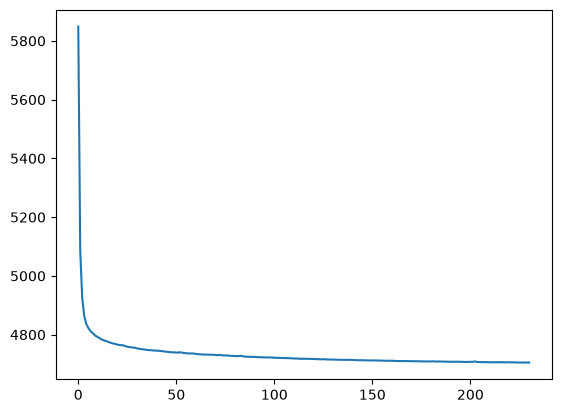

In [23]:
elbo = mvi_model.history['elbo_train']
elbo['elbo_validation'] = mvi_model.history['elbo_validation']

plt.plot(elbo['elbo_train'])

### multiome_latent_transfer

In [24]:
# Convert the cell barcode to the observable matrix X_scvi which neighbors and UMAP can be calculated from
mdata.obsm['X_multivi'] = mvi_model.get_latent_representation()

In [30]:
mdata.obs["modality_group"] = hv_mdata.obs["modality_group"]

In [25]:
# Calculate nearest neighbors and the UMAP from the X_scvi observable matrix
sc.pp.neighbors(mdata, use_rep='X_multivi')
sc.tl.umap(mdata, min_dist=0.3)

In [26]:
# Calculate the leiden distance from the nearest neighbors, use a couple resolutions
sc.tl.leiden(mdata, key_added='leiden', flavor = 'igraph')

In [27]:
# Transfer leiden clusters to rna and atac modalities
barcode2leiden = mdata.obs['leiden'].to_dict()
mdata.mod['rna'].obs['leiden'] = [barcode2leiden[x] for x in mdata.mod['rna'].obs_names]
mdata.mod['atac'].obs['leiden'] = [barcode2leiden[x] for x in mdata.mod['atac'].obs_names]

... storing 'Sample_ID' as categorical


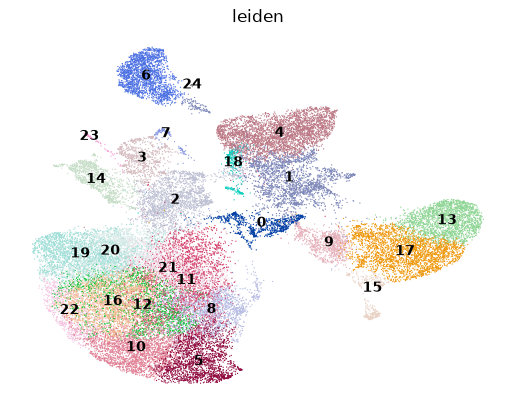

In [32]:
mu.pl.umap(
    mdata,
    color = ['leiden'],
    frameon = False,
    legend_loc = 'on data'
)

... storing 'Sample_ID' as categorical


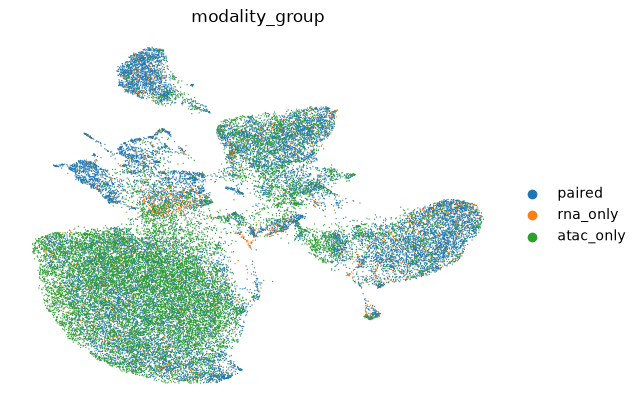

In [ ]:
mu.pl.umap(
    mdata,
    color = ['modality_group'],
    frameon = False,
)

## Annotation

### multiome_cell_type_annotation

While the snRNAseq 

In [15]:
# Create the DataFrame of canonical gene markers (This can be expanded)
marker_gene_df = pd.read_csv(work_dir + 'input/first_pass_genes.csv')
marker_gene_df

,source,target
0,Astro,AQP4
1,Astro,GFAP
2,DaN,SLC6A3
3,DaN,TH
4,EC,CLDN5
5,EC,PECAM1
6,ExN,SLC17A7
7,ExN,SATB2
8,EpC,TTR
9,EpC,FOXJ1


In [19]:
# Use only the rna modality
adata = mdata.mod['rna']

# Ensure the leiden clusters are the same between modalities
barcode2leiden = mdata.obs['leiden'].to_dict()
adata.obs['multiome_leiden'] = [barcode2leiden[x] for x in adata.obs_names]
adata

AnnData object with n_obs × n_vars = 23019 × 36601
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_rb', 'pct_counts_rb', 'total_counts_mt', 'pct_counts_mt', 'Sample_ID', 'Use_batch', 'Age', 'PMI', 'Sex', 'Brain_bank', 'Primary Diagnosis', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'predicted_doublet', 'leiden', 'celltype', 'multiome_leiden'
    var: 'gene_ids', 'mt', 'rb', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'celltype_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'umap'
    obsm: 'X_scvi', 'X_umap', 'padj_ulm', 'score_ulm'
    layers: 'counts', 'cpm', 'log-norm'
    obsp: 'connectivities', 'distances'

In [20]:
# Run over-represenation analysis based on cell markers
# provided in the marker_gene_df DataFrame.
dc.mt.ulm(
    adata,
    net = marker_gene_df,
    tmin=2,
    raw = False,
    layer = 'log-norm'
)

In [21]:
# Convert the ORA AnnData object to numpy array to rank
score = dc.pp.get_obsm(adata, key="score_ulm")
df = dc.tl.rankby_group(adata=score, groupby='multiome_leiden', reference="rest", method="wilcoxon")

In [22]:
# Apply the best ranked cell type to a cluster-celltype dictionary
annotation_dict = df.groupby('group').head(1).set_index('group')['name'].to_dict()

# Apply the dictionary to the MuData object
mdata.obs['celltype'] = [annotation_dict[clust] for clust in mdata.obs['leiden']]

/tmp/ipykernel_1166891/890499784.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  annotation_dict = df.groupby('group').head(1).set_index('group')['name'].to_dict()


... storing 'celltype' as categorical


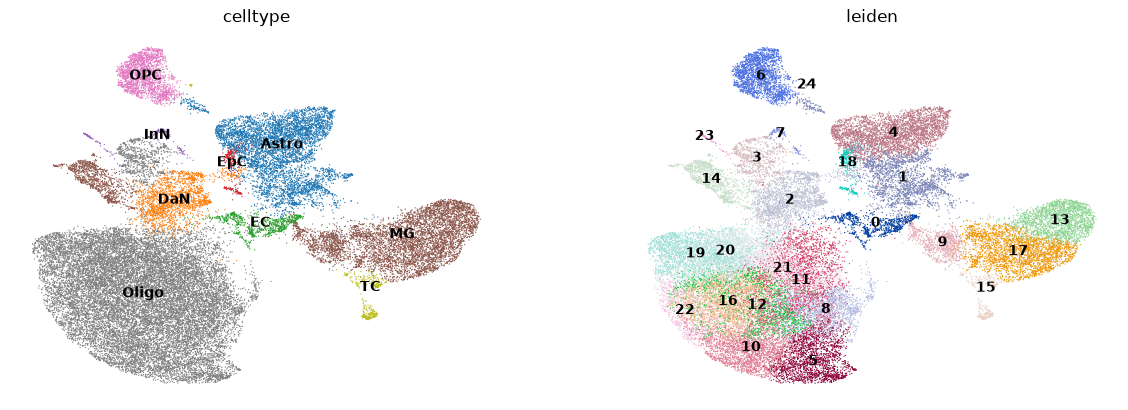

In [23]:
# Visualize the results
mu.pl.umap(
    mdata, 
    color = ['celltype', 'leiden'],
    legend_loc = 'on data',
    frameon = False
)

In [ ]:
# Port the cell types to the other layers
barcode2celltype = 
mdata.mod['atac'] = []

... storing 'multiome_leiden' as categorical


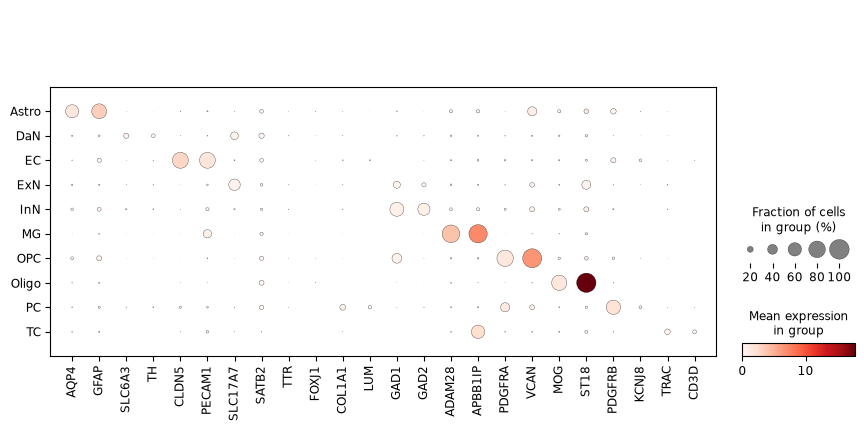

In [24]:
sc.pl.dotplot(
    mdata.mod['rna'],
    marker_gene_df['target'],
    groupby = 'celltype',
    use_raw = False,
    layer = 'log-norm',
)

### multiome_pychromvar

One incredibly useful analysis we can run is the inference of transcription factor enrichment on a per nuclei basis. This is done using the package [pychromVAR](https://github.com/pinellolab/pychromVAR), a python port of [chromVAR](https://www.nature.com/articles/nmeth.4401) from the Greenleaf lab. We use the python port as the original packages were not built to scale to millions of nuclei/cells, and subsequently some of the methods are not very memory efficient. In the Snakemake pipeline this is addressed by chunking the dataset, but to finish in a reasonable amount of time (days) this still requires Tb of memory.

This is still an inferred modality, but it is much more reliable than using gene expression data as a proxy for transcription factor activity.

In [115]:
# Get reference genome and sequences at peaks
pc.add_peak_seq(
    atac, 
    genome_file = ref_genome, 
    delimiter = ':|-' 
)

100%|██████████| 608977/608977 [00:02<00:00, 265192.05it/s]


In [116]:
# Correct for GC bias
pc.add_gc_bias(atac)
atac

/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/pychromvar/preprocessing.py:117: FutureWarning: The method uns_keys is deprecated and will be removed in the future. Use uns instead of uns_keys. (e.g. `k in adata.uns` or `sorted(adata.uns)`)
  assert "peak_seq" in adata.uns_keys(), "Cannot find sequences, please first run add_peak_seq!"
100%|██████████| 608977/608977 [00:02<00:00, 215346.86it/s]


AnnData object with n_obs × n_vars = 34934 × 608977
    obs: 'sample', 'n_fragment', 'tsse'
    var: 'count', 'selected', 'gc_bias'
    uns: 'spectral_eigenvalue', 'peak_seq'
    obsm: 'X_spectral', 'X_umap'
    obsp: 'distances'

In [117]:
reads_per_peak = np.log1p(atac.X.sum(axis=0)) / np.log(10)
reads_per_peak

matrix([[1.75587484, 1.92427922, 2.521138  , ..., 2.50650497, 2.38201707,
         2.73798724]], shape=(1, 608977))

In [120]:
atac.var['gc_bias'].values

array([0.508, 0.55 , 0.466, ..., 0.482, 0.494, 0.6  ], shape=(608977,))

In [125]:
"""pc.get_bg_peaks(mdata)"""
import scipy as sp
from pynndescent import NNDescent
niterations=50
n_jobs=-1
reads_per_peak = np.log1p(atac.X.sum(axis=0)) / np.log(10)

# here if reads_per_peak is a numpy matrix, convert it to array
if isinstance(reads_per_peak, np.matrix):
    reads_per_peak = np.squeeze(np.asarray(reads_per_peak))

mat = np.array([reads_per_peak, atac.var['gc_bias'].values])
chol_cov_mat = np.linalg.cholesky(np.cov(mat))
trans_norm_mat = sp.linalg.solve_triangular(
    a=chol_cov_mat, b=mat, lower=True).transpose()

index = NNDescent(trans_norm_mat, metric="euclidean",
                    n_neighbors=niterations, n_jobs=n_jobs)
knn_idx, _ = index.query(trans_norm_mat, niterations)

atac.varm['bg_peaks'] = knn_idx

In [127]:
jdb_obj = jaspardb(release='JASPAR2026')
motifs = jdb_obj.fetch_motifs(collection='CORE', species=9606)

In [128]:
pc.match_motif(atac, motifs=motifs)

/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/pychromvar/match_motif.py:48: FutureWarning: The method uns_keys is deprecated and will be removed in the future. Use uns instead of uns_keys. (e.g. `k in adata.uns` or `sorted(adata.uns)`)
  assert "peak_seq" in adata.uns_keys(), "Cannot find sequences, please first run add_peak_seq!"
100%|██████████| 608977/608977 [11:42<00:00, 866.82it/s]


In [ ]:
# Find how the individual nuclei TF motif enrichments deviate from the main score
chromvar = pc.compute_deviations(
    atac,
    n_jobs = 1
)
chromvar

/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/pychromvar/compute_deviations.py:40: FutureWarning: The method varm_keys is deprecated and will be removed in the future. Use varm instead of varm_keys. (e.g. `k in adata.varm` or `adata.varm.keys() | {'u'}`)
  assert "bg_peaks" in adata.varm_keys(


In [ ]:
# Add the 
mdata.mod['chromvar'] = chromvar

In [ ]:
mu.pl.umap(
    mdata,
    color = 'MA0473.4.ELF1',
    palette = 'PuOr_r',
    vcenter = 0
)

## Export the dataset

In [ ]:
mdata.write_h5mu(work_dir + 'data/08_multiome.h5mu', compression = 'gzip')